# Import and predefining

In [1]:
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn.functional as F
from sklearn import set_config
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from torch import nn
from torch.utils.data import DataLoader, TensorDataset, random_split
from torchvision import datasets, models, transforms

set_config(display="text")

random_state = 42

torch.manual_seed(random_state)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [2]:
from dataclasses import dataclass


@dataclass
class ModelResult:
    name: str
    confusion_matrix: np.ndarray
    accuracy_score: float

    def __sub__(self, other) -> "ModelResult":
        if type(other) != type(self):
            raise NotImplementedError

        model_result = ModelResult(
            name=self.name + other.name,
            confusion_matrix=self.confusion_matrix - other.confusion_matrix,
            accuracy_score=self.accuracy_score - other.accuracy_score,
        )
        return model_result

In [3]:
def plot_heatmap(
    dataframe: pd.DataFrame | np.ndarray,
    figsize: tuple[int, int] = (6, 5),
    cmap: str | None = None,
    vmin: float | None = None,
    vmax: float | None = None,
    rotation: int = 45,
    xticklabels: list[str] | bool = True,
    yticklabels: list[str] | bool = True,
    title_name: str | None = None,
    ax: plt.Axes | None = None,  # pyright: ignore[reportPrivateImportUsage]
) -> None:
    if ax is None:
        plt.figure(figsize=figsize)

    sns.heatmap(
        dataframe,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        linewidths=0.5,
        annot=True,
        fmt=".2f",
        annot_kws={"size": 7},
        xticklabels=xticklabels,
        yticklabels=yticklabels,
        ax=ax,
    )

    if ax is None:
        plt.xticks(rotation=rotation, ha="right", fontsize=9)
        plt.yticks(rotation=0, fontsize=9)
        if title_name:
            plt.title(title_name)
        plt.show()
    else:
        ax.tick_params(axis="x", rotation=rotation, labelsize=9)
        ax.tick_params(axis="y", rotation=0, labelsize=9)
        if title_name:
            ax.set_title(title_name)


def plot_table(
    cellText: np.ndarray | pd.DataFrame,
    rowLabels: list | None = None,
    colLabels: list | None = None,
    title_name: str | None = None,
    fontsize: int = 10,
    scale: tuple[float, float] = (1.7, 1.5),
    figsize: tuple[int, int] = (8, 3),
) -> None:
    fig, ax = plt.subplots(figsize=figsize)
    ax.axis("off")

    table = ax.table(
        cellText=cellText,
        rowLabels=rowLabels,
        colLabels=colLabels,
        cellLoc="center",
        loc="center",
    )

    table.auto_set_font_size(False)
    table.set_fontsize(fontsize)
    table.scale(*scale)
    if title_name:
        plt.title(title_name)
    plt.show()

# 1. Повнозв'язані нейронні мережі
1. Візьміть датасет, з яким ви працювали в лабораторній роботі №1.
1. Побудуйте повнозв'язану нейронну мережу (MLP) для задачі класифікації.
1. Навчіть модель на тренувальній вибірці та оцініть її якість на тестовій.
1. Побудуйте learning curves (train/validation loss) та проаналізуйте процес навчання моделі. Чи спостерігається перенавчання?
1. Порівняйте результати нейронної мережі з результатами класичних алгоритмів машинного навчання з Lab 1.
1. Зробіть висновки.

## Візьміть датасет, з яким ви працювали в лабораторній роботі №1

In [4]:
label_encoder_lab_1 = LabelEncoder()
scaler = StandardScaler()
datapath_lab_1 = Path("../lab1/data/Date_Fruit_Datasets.xlsx")
raw_data_lab_1 = pd.read_excel(datapath_lab_1)

target_name = "Class"
features_lab_1 = raw_data_lab_1.drop(target_name, axis=1)
target_lab_1 = raw_data_lab_1[target_name]

target_encoded_lab_1 = label_encoder_lab_1.fit_transform(target_lab_1)

full_X_train_lab_1, X_test_lab_1, full_y_train_lab_1, y_test_lab_1 = train_test_split(
    features_lab_1,
    target_encoded_lab_1,
    random_state=random_state,
    test_size=0.25,
    stratify=target_encoded_lab_1,
)

X_train_lab_1, X_val_lab_1, y_train_lab_1, y_val_lab_1 = train_test_split(
    full_X_train_lab_1,
    full_y_train_lab_1,
    test_size=0.15,
    stratify=full_y_train_lab_1,
    random_state=random_state,
)

X_train_lab_1_scaled = scaler.fit_transform(X_train_lab_1)
X_val_lab_1_scaled = scaler.transform(X_val_lab_1)
X_test_lab_1_scaled = scaler.transform(X_test_lab_1)

In [5]:
(
    X_train_lab_1_scaled.shape,
    X_val_lab_1_scaled.shape,
    X_test_lab_1_scaled.shape,
    y_train_lab_1.shape,
    y_val_lab_1.shape,
    y_test_lab_1.shape,
)

((572, 34), (101, 34), (225, 34), (572,), (101,), (225,))

In [6]:
len(label_encoder_lab_1.classes_)

7

## Побудуйте повнозв'язану нейронну мережу (MLP) для задачі класифікації

In [7]:
class MLP(nn.Module):
    def __init__(self, in_features: int, out_features: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(32, out_features),  # logits
        )

    def forward(self, x):
        logits = self.net(x)  # [B, 34] -> [B, 7]
        return logits  # [B, 7]


in_features = X_train_lab_1_scaled.shape[-1]
out_features = len(label_encoder_lab_1.classes_)
model = MLP(in_features, out_features).to(device)
print(model)

MLP(
  (net): Sequential(
    (0): Linear(in_features=34, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Dropout(p=0.25, inplace=False)
    (5): Linear(in_features=32, out_features=7, bias=True)
  )
)


## Навчіть модель на тренувальній вибірці та оцініть її якість на тестовій

In [8]:
model = MLP(in_features, out_features).to(device)

num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Trainable params:", num_params)
print()

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-3)

patience = 10
n_epochs = 1000
best_model_path = "best_model.pth"
batch_size = 32

X_train_t = torch.as_tensor(X_train_lab_1_scaled, dtype=torch.float32, device=device)
X_val_t = torch.as_tensor(X_val_lab_1_scaled, dtype=torch.float32, device=device)
y_train_t = torch.as_tensor(y_train_lab_1, dtype=torch.long, device=device)
y_val_t = torch.as_tensor(y_val_lab_1, dtype=torch.long, device=device)

train_loader = DataLoader(
    TensorDataset(X_train_t.to(device), y_train_t.to(device)),
    batch_size=batch_size,
    shuffle=True,
)
val_loader = DataLoader(
    TensorDataset(X_val_t.to(device), y_val_t.to(device)),
    batch_size=batch_size,
    shuffle=False,
)

X_train_len = len(X_train_t)
X_val_len = len(X_val_t)


def train_and_eval(
    model,
    criterion,
    optimizer,
    patience: int,
    n_epochs: int,
    best_model_path: str,
    X_train_len,
    X_val_len,
    train_loader,
    val_loader,
    device: str | torch.Device,
) -> tuple[list[float], list[float], list[float], list[float]]:
    best_val_loss = float("inf")
    epochs_no_improve = 0
    train_loss_history: list[float] = []
    train_accuracy_history: list[float] = []
    val_loss_history: list[float] = []
    val_accuracy_history: list[float] = []
    for epoch in range(n_epochs):
        # --- train ---
        model.train()
        train_loss = 0.0
        train_accuracy = 0.0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            train_accuracy += (out.argmax(dim=1) == y).sum().item()
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * x.size(0)
        train_loss /= X_train_len
        train_accuracy /= X_train_len

        # --- validation ---
        model.eval()
        val_loss = 0.0
        val_accuracy = 0.0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                out = model(x)
                loss = criterion(out, y)
                val_accuracy += (out.argmax(dim=1) == y).sum().item()
                val_loss += loss.item() * x.size(0)
        val_loss /= X_val_len
        val_accuracy /= X_val_len

        train_loss_history.append(train_loss)
        train_accuracy_history.append(train_accuracy)
        val_loss_history.append(val_loss)
        val_accuracy_history.append(val_accuracy)
        print(
            f"[{epoch + 1:02d}] train_loss={train_loss:.4f} | train_accuracy={train_accuracy:.4f} | val_loss={val_loss:.4f} | val_accuracy={val_accuracy:.4f}"
        )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            epochs_no_improve = 0
            torch.save(model.state_dict(), best_model_path)
            print("Saved best model")
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print("Early stopping epoch: ", epoch)
                break

    return (
        train_loss_history,
        train_accuracy_history,
        val_loss_history,
        val_accuracy_history,
    )


train_loss_history, train_accuracy_history, val_loss_history, val_accuracy_history = (
    train_and_eval(
        model,
        criterion,
        optimizer,
        patience,
        n_epochs,
        best_model_path,
        X_train_len,
        X_val_len,
        train_loader,
        val_loader,
        device,
    )
)

Trainable params: 4551



[01] train_loss=1.7933 | train_accuracy=0.4073 | val_loss=1.6336 | val_accuracy=0.6535
Saved best model
[02] train_loss=1.4941 | train_accuracy=0.6189 | val_loss=1.2398 | val_accuracy=0.6535
Saved best model
[03] train_loss=1.1116 | train_accuracy=0.6521 | val_loss=0.8904 | val_accuracy=0.6832
Saved best model
[04] train_loss=0.8613 | train_accuracy=0.6941 | val_loss=0.7172 | val_accuracy=0.7327
Saved best model
[05] train_loss=0.7206 | train_accuracy=0.7395 | val_loss=0.6269 | val_accuracy=0.7426
Saved best model
[06] train_loss=0.6243 | train_accuracy=0.7710 | val_loss=0.5643 | val_accuracy=0.7525
Saved best model
[07] train_loss=0.5665 | train_accuracy=0.7762 | val_loss=0.5143 | val_accuracy=0.7525
Saved best model
[08] train_loss=0.5016 | train_accuracy=0.8147 | val_loss=0.4843 | val_accuracy=0.7822
Saved best model
[09] train_loss=0.5091 | train_accuracy=0.7815 | val_loss=0.4580 | val_accuracy=0.7822
Saved best model
[10] train_loss=0.4514 | train_accuracy=0.8357 | val_loss=0.4327

## Побудуйте learning curves (train/validation loss) та проаналізуйте процес навчання моделі. Чи спостерігається перенавчання?

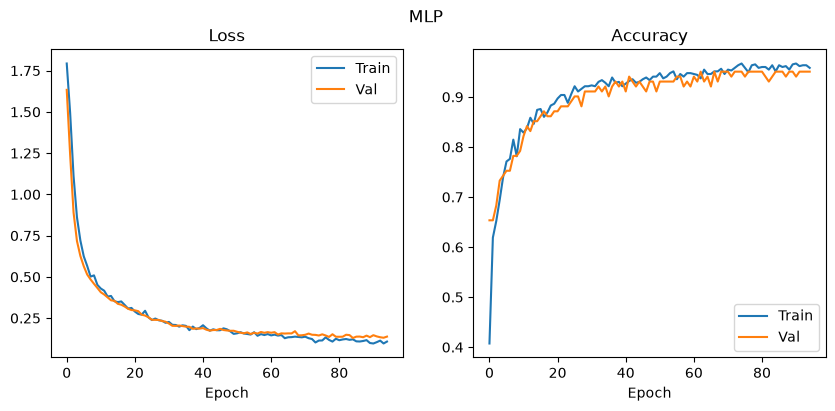

In [9]:
def plot_learning_curves(
    train_loss_history: list[float],
    train_accuracy_history: list[float],
    val_loss_history: list[float],
    val_accuracy_history: list[float],
    title: str,
):
    fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(10, 4))

    sns.lineplot(train_loss_history, label="Train", ax=ax1)
    sns.lineplot(val_loss_history, label="Val", ax=ax1)

    sns.lineplot(train_accuracy_history, label="Train", ax=ax2)
    sns.lineplot(val_accuracy_history, label="Val", ax=ax2)

    ax1.set_title("Loss")
    ax1.set_xlabel("Epoch")

    ax2.set_title("Accuracy")
    ax2.set_xlabel("Epoch")

    plt.suptitle(title)
    plt.show()


plot_learning_curves(
    train_loss_history,
    train_accuracy_history,
    val_loss_history,
    val_accuracy_history,
    title="MLP",
)

Явного перенавчання не спостерігається: train і validation loss знижуються майже синхронно, розрив між кривими залишається малим, а val loss виходить на плато без зростання. Імовірно, цьому сприяють невелика ємність мережі (4551 параметр), dropout, L2-регуляризація та рання зупинка, а також те, що класи в датасеті добре розділяються. Найкращі ваги отримано на епосі 85 при val_loss = 0.1295, після чого рання зупинка спрацювала на епосі 95, коли протягом 10 епох val loss перестав покращуватися.

## Порівняйте результати нейронної мережі з результатами класичних алгоритмів машинного навчання з Lab 1

In [10]:
pca_svc = Pipeline(
    [
        ("pca", PCA(n_components=9, random_state=random_state)),
        ("svc", SVC(C=10, gamma=0.01, kernel="rbf", random_state=random_state)),
    ]
)
pca_svc.fit(X_train_lab_1_scaled, y_train_lab_1)
old_pred = pca_svc.predict(X_test_lab_1_scaled)

In [11]:
model.load_state_dict(torch.load(best_model_path, weights_only=True))

X_test_t = torch.as_tensor(X_test_lab_1_scaled, dtype=torch.float32, device=device)
y_test_t = torch.as_tensor(y_test_lab_1, dtype=torch.long, device=device)

model.eval()
with torch.no_grad():
    y_pred = model(X_test_t).argmax(dim=1).cpu().numpy()

labels = label_encoder_lab_1.classes_

mlp_score = accuracy_score(y_test_lab_1, y_pred)
print(f"MLP Test accuracy: {mlp_score:.4f}")
mlp_report = classification_report(y_test_lab_1, y_pred, target_names=labels)
print(mlp_report)

svc_score = accuracy_score(y_test_lab_1, old_pred)
print(f"SVC Test accuracy: {svc_score:.4f}")
svc_report = classification_report(y_test_lab_1, old_pred, target_names=labels)
print(svc_report)

MLP Test accuracy: 0.9511
              precision    recall  f1-score   support

       BERHI       1.00      0.94      0.97        16
      DEGLET       0.88      0.84      0.86        25
       DOKOL       0.98      0.96      0.97        51
       IRAQI       0.95      1.00      0.97        18
      ROTANA       0.95      0.98      0.96        42
      SAFAVI       0.98      1.00      0.99        50
       SOGAY       0.87      0.87      0.87        23

    accuracy                           0.95       225
   macro avg       0.94      0.94      0.94       225
weighted avg       0.95      0.95      0.95       225

SVC Test accuracy: 0.9467
              precision    recall  f1-score   support

       BERHI       1.00      0.88      0.93        16
      DEGLET       0.91      0.80      0.85        25
       DOKOL       0.96      0.98      0.97        51
       IRAQI       0.90      1.00      0.95        18
      ROTANA       0.98      0.98      0.98        42
      SAFAVI       0.96   

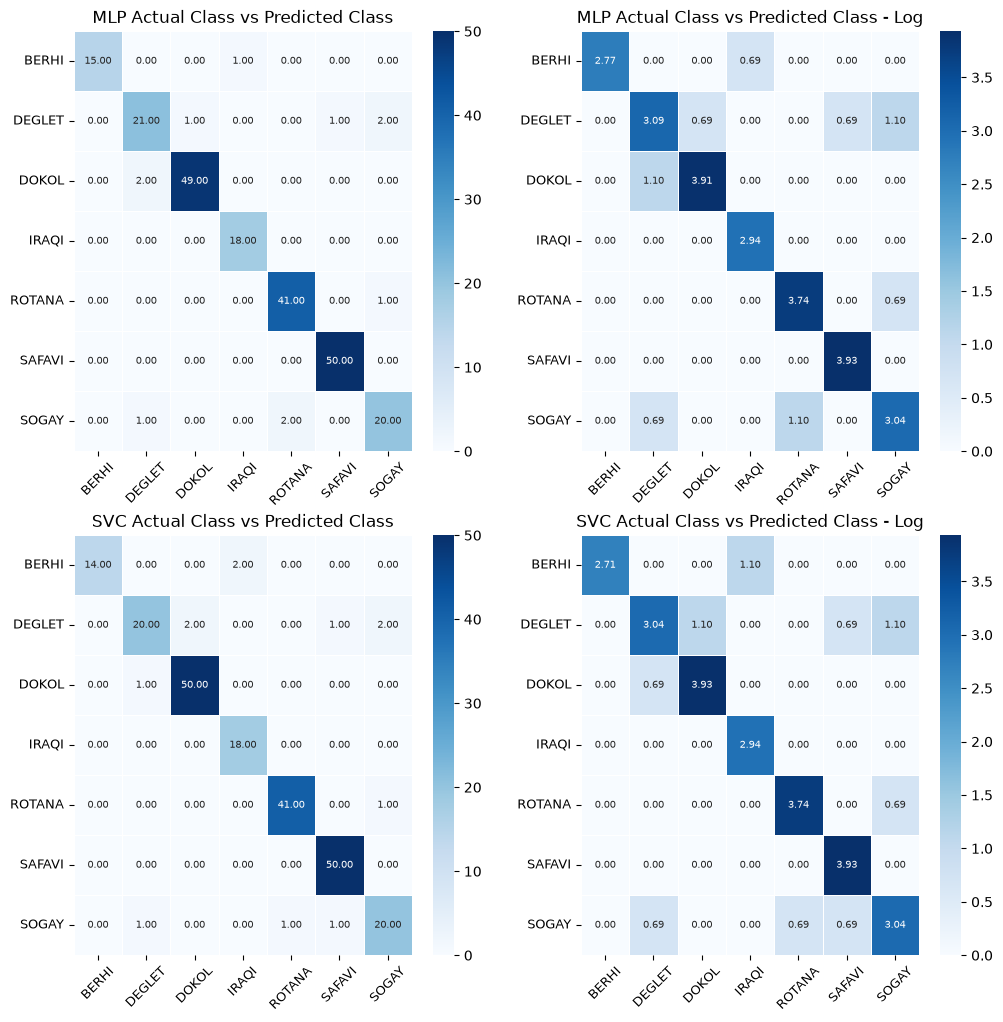

In [12]:
conf_matrx = confusion_matrix(y_test_lab_1, y_pred)
old_conf_matrx = confusion_matrix(y_test_lab_1, old_pred)

fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(nrows=2, ncols=2, figsize=(12, 12))
figsize_heatmap = (6, 5)
plot_heatmap(
    dataframe=conf_matrx,
    figsize=figsize_heatmap,
    xticklabels=labels,
    yticklabels=labels,  # pyright: ignore[reportArgumentType]
    cmap="Blues",
    title_name="MLP Actual Class vs Predicted Class",
    ax=ax1,
)
plot_heatmap(
    dataframe=np.log1p(conf_matrx),
    figsize=figsize_heatmap,
    xticklabels=labels,
    yticklabels=labels,  # pyright: ignore[reportArgumentType]
    cmap="Blues",
    title_name="MLP Actual Class vs Predicted Class - Log",
    ax=ax2,
)
plot_heatmap(
    dataframe=old_conf_matrx,
    figsize=figsize_heatmap,
    xticklabels=labels,
    yticklabels=labels,  # pyright: ignore[reportArgumentType]
    cmap="Blues",
    title_name="SVC Actual Class vs Predicted Class",
    ax=ax3,
)
plot_heatmap(
    dataframe=np.log1p(old_conf_matrx),
    figsize=figsize_heatmap,
    xticklabels=labels,
    yticklabels=labels,  # pyright: ignore[reportArgumentType]
    cmap="Blues",
    title_name="SVC Actual Class vs Predicted Class - Log",
    ax=ax4,
)

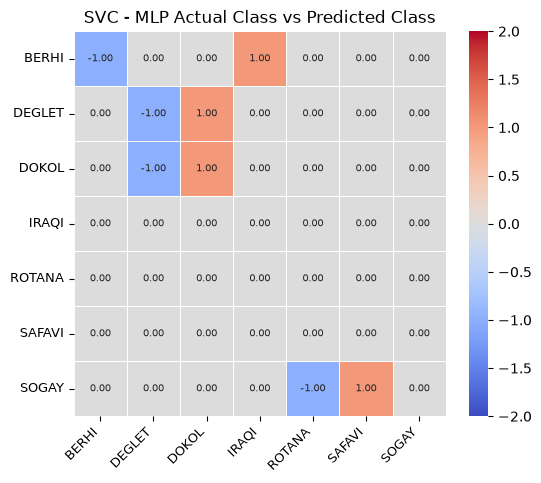

In [13]:
svc_model_result = ModelResult(
    name="SVC",
    confusion_matrix=old_conf_matrx,
    accuracy_score=svc_score,  # pyright: ignore[reportArgumentType]
)


mlp_model_result = ModelResult(
    name="MLP",
    confusion_matrix=conf_matrx,
    accuracy_score=mlp_score,  # pyright: ignore[reportArgumentType]
)

diff_model_result = svc_model_result - mlp_model_result

figsize_heatmap = (6, 5)
plot_heatmap(
    dataframe=diff_model_result.confusion_matrix,
    figsize=figsize_heatmap,
    xticklabels=labels,
    yticklabels=labels,  # pyright: ignore[reportArgumentType]
    cmap="coolwarm",
    title_name="SVC - MLP Actual Class vs Predicted Class",
    vmin=-2,
    vmax=2,
)

## Зробіть висновки

Повнозв'язна нейронна мережа на стандартизованих ознаках досягла тестової точності 0.9511 та макросередній F1 0.94, а `SVC` із `PCA` на 9 компонентах 0.9467 та 0.93 за однакового обсягу навчальних даних. Різниця становить один об'єкт із 225, тому моделі слід вважати рівноцінними за якістю. На відміну від `SVC`, мережа працює з усіма 34 ознаками без попереднього стискання `PCA`.

Окрема валідаційна вибірка, L2-регуляризація, dropout та рання зупинка дозволили уникнути помітного перенавчання та отримати об'єктивну оцінку на ізольованих тестових даних.

Обидві моделі без помилок розпізнають усі тестові зразки сортів `'IRAQI'` та `'SAFAVI'` (recall 1.00). Покласові відмінності між ними мінімальні: `MLP` правильно класифікує на один об'єкт більше в класах `'BERHI'` (15 проти 14) та `'DEGLET'` (21 проти 20), тоді як `SVC` випереджає його на один об'єкт у класі `'DOKOL'` (50 проти 49); у класах `'ROTANA'` та `'SOGAY'` результати збігаються. Найнижчий recall в обох моделей мають сорти `'DEGLET'` (0.84 для `MLP` та 0.80 для `SVC`) і `'SOGAY'` (0.87 для обох), тобто саме ці класи залишаються найскладнішими для розпізнавання.

# 2. Згорткові нейронні мережі
1. Оберіть датасет зображень для задачі класифікації. 
1. Коротко опишіть датасет (класи, кількість зображень) та візуалізуйте приклади зображень для кожного класу. 
1. Вирішіть задачу класифікації двома способами.
    1. a)
        1. Побудуйте просту CNN (2–3 convolutional шари + fully connected layer).
        1. Навчіть модель на обраному датасеті.
        1. Побудуйте learning curves (train/validation loss) та проаналізуйте процес навчання.
    1. b) 
        1. Використайте попередньо натреновану модель (наприклад, ResNet, EfficientNet, MobileNet або іншу pretrained CNN).
        1. Замініть вихідний класифікатор відповідно до кількості класів вашого датасету та проведіть донавчання моделі.
1. Порівняйте CNN, навчену з нуля, та pretrained модель:  якість класифікації;  процес і швидкість збіжності;  learning curves;  вплив обсягу тренувальних даних.
1. Зробіть висновки.

## Оберіть датасет зображень для задачі класифікації

In [14]:
datapath = Path("../lab3/data/")

transform = transforms.ToTensor()

train_full = datasets.ImageFolder(datapath / "train", transform=transform)
test_dataset = datasets.ImageFolder(datapath / "test", transform=transform)

img_labels_str = train_full.classes
targets = np.array(train_full.targets)
img_labels = np.unique(targets)

def preload_to_device(dataset: datasets.ImageFolder, target_device: torch.device) -> TensorDataset:
    loader = DataLoader(dataset, batch_size=1024, shuffle=False)
    xs, ys = [], []
    for x, y in loader:
        xs.append(x)
        ys.append(y)
    return TensorDataset(torch.cat(xs).to(target_device), torch.cat(ys).to(target_device))

cache_path = datapath / "../train_cache.pt"
if cache_path.exists():
    x_all, y_all = torch.load(cache_path, weights_only=True)
    full_tensor_dataset = TensorDataset(x_all.to(device), y_all.to(device))
else:
    full_tensor_dataset = preload_to_device(train_full, device)
    torch.save(full_tensor_dataset.tensors, cache_path)

generator = torch.Generator().manual_seed(random_state)
train_dataset, val_dataset = random_split(full_tensor_dataset, [0.9, 0.1], generator=generator)

## Коротко опишіть датасет (класи, кількість зображень) та візуалізуйте приклади зображень для кожного класу

2 Classes : ['FAKE', 'REAL']
Image shape: (3, 32, 32)
Train size: 90000, Val size: 10000, Test size: 20000
	FAKE: train_full=50000, test=10000
	REAL: train_full=50000, test=10000


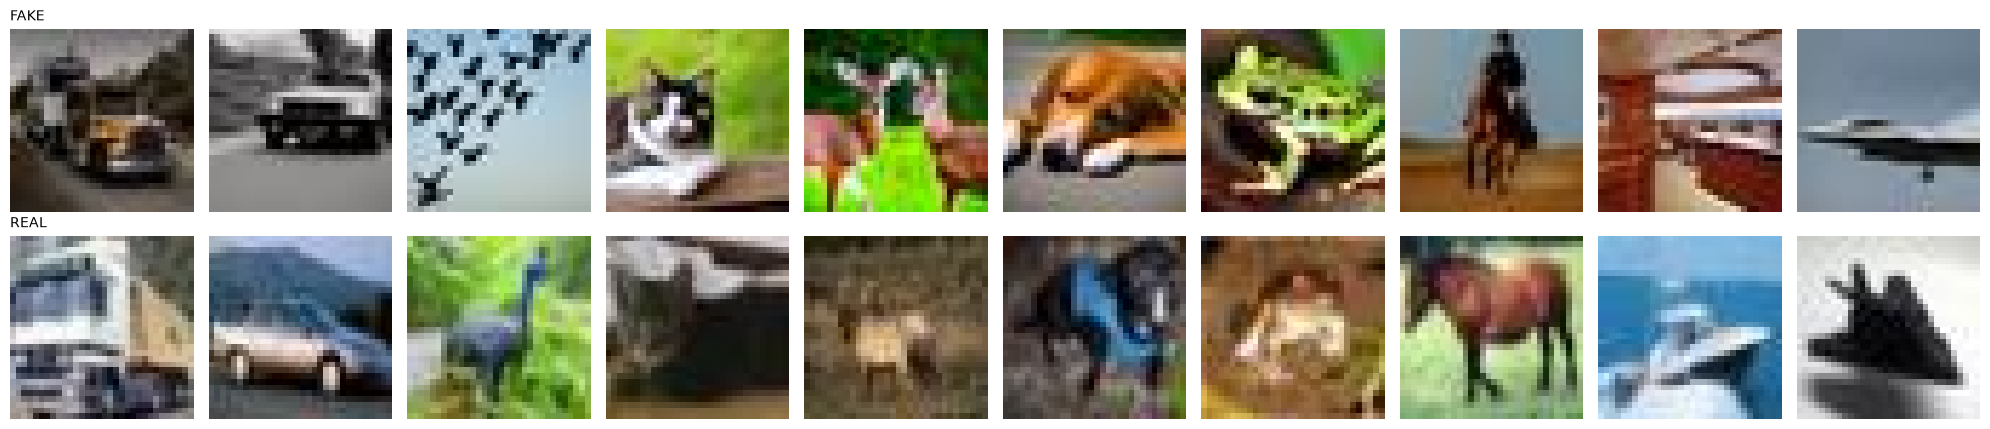

In [15]:
sample_img, _ = train_full[0]
print(f"{len(img_labels_str)} Classes : {img_labels_str}")
print(f"Image shape: {tuple(sample_img.shape)}")
print(
    f"Train size: {len(train_dataset)}, Val size: {len(val_dataset)}, Test size: {len(test_dataset)}"
)

train_counts = np.bincount(train_full.targets)
test_counts = np.bincount(test_dataset.targets)
for idx, class_name in enumerate(img_labels_str):
    print(f"\t{class_name}: train_full={train_counts[idx]}, test={test_counts[idx]}")

n_classes = len(img_labels_str)
n_samples = 10
fig, axes = plt.subplots(
    nrows=n_classes, ncols=n_samples, figsize=(n_samples * 2, n_classes * 2.2)
)
if n_classes == 1:
    axes = np.expand_dims(axes, axis=0)

for row_idx, class_idx in enumerate(img_labels):
    class_indices = np.where(targets == class_idx)[0][:n_samples]
    for col_idx, img_idx in enumerate(class_indices):
        img, _ = train_full[img_idx]
        ax = axes[row_idx, col_idx]
        ax.imshow(img.permute(1, 2, 0))
        ax.axis("off")
        if col_idx == 0:
            ax.set_title(img_labels_str[class_idx], loc="left", fontsize=10)

plt.tight_layout()
plt.show()

## Вирішіть задачу класифікації двома способами

### a)

#### Побудуйте просту CNN (2–3 convolutional шари + fully connected layer)

In [16]:
class CNN(nn.Module):
    def __init__(self, in_features: int, out_features: int):
        super().__init__()
        self.conv1 = nn.Conv2d(in_features, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.adaptive_pool = nn.AdaptiveAvgPool2d((4, 4))
        self.dropout = nn.Dropout(0.25)

        self.fc1 = nn.Linear(64 * 4 * 4, 128)
        self.fc2 = nn.Linear(128, out_features)

    def forward(self, x):
        # x: [B, 3, 32, 32]
        x = F.relu(self.conv1(x))  # [B, 32, 32, 32]
        x = self.pool(x)  # [B, 32, 16, 16]
        x = F.relu(self.conv2(x))  # [B, 64, 16, 16]
        x = self.pool(x)  # [B, 64, 8, 8]
        x = self.adaptive_pool(x)  # [B, 64, 4, 4]
        x = self.dropout(x)
        x = torch.flatten(x, 1)  # [B, 64*4*4]
        x = F.relu(self.fc1(x))  # [B, 128]
        logits = self.fc2(x)  # [B, 2]
        return logits


in_features = sample_img.shape[0]
out_features = len(img_labels)
model = CNN(in_features, out_features).to(device)
print(model)

CNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (adaptive_pool): AdaptiveAvgPool2d(output_size=(4, 4))
  (dropout): Dropout(p=0.25, inplace=False)
  (fc1): Linear(in_features=1024, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=2, bias=True)
)


#### Навчіть модель на обраному датасеті

In [17]:
model_cnn = CNN(in_features, out_features).to(device)

num_params = sum(p.numel() for p in model_cnn.parameters() if p.requires_grad)
print("Trainable params:", num_params)
print()

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_cnn.parameters(), lr=1e-3, weight_decay=1e-3)

patience = 10
n_epochs = 100
best_model_path_cnn = "best_model_cnn.pth"
batch_size = 256

train_loader_cnn = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader_cnn = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

(
    train_loss_history_cnn,
    train_accuracy_history_cnn,
    val_loss_history_cnn,
    val_accuracy_history_cnn,
) = train_and_eval(
    model_cnn,
    criterion,
    optimizer,
    patience,
    n_epochs,
    best_model_path_cnn,
    len(train_dataset),
    len(val_dataset),
    train_loader_cnn,
    val_loader_cnn,
    device,
)

Trainable params: 150850

[01] train_loss=0.4118 | train_accuracy=0.8085 | val_loss=0.2900 | val_accuracy=0.8849
Saved best model
[02] train_loss=0.2910 | train_accuracy=0.8798 | val_loss=0.2507 | val_accuracy=0.8992
Saved best model
[03] train_loss=0.2564 | train_accuracy=0.8960 | val_loss=0.2258 | val_accuracy=0.9070
Saved best model
[04] train_loss=0.2386 | train_accuracy=0.9044 | val_loss=0.2253 | val_accuracy=0.9057
Saved best model
[05] train_loss=0.2197 | train_accuracy=0.9120 | val_loss=0.2353 | val_accuracy=0.9009
[06] train_loss=0.2114 | train_accuracy=0.9157 | val_loss=0.1973 | val_accuracy=0.9177
Saved best model
[07] train_loss=0.2085 | train_accuracy=0.9175 | val_loss=0.1818 | val_accuracy=0.9312
Saved best model
[08] train_loss=0.2009 | train_accuracy=0.9207 | val_loss=0.1759 | val_accuracy=0.9338
Saved best model
[09] train_loss=0.1913 | train_accuracy=0.9248 | val_loss=0.1722 | val_accuracy=0.9331
Saved best model
[10] train_loss=0.1885 | train_accuracy=0.9261 | val_lo

#### Побудуйте learning curves (train/validation loss) та проаналізуйте процес навчання

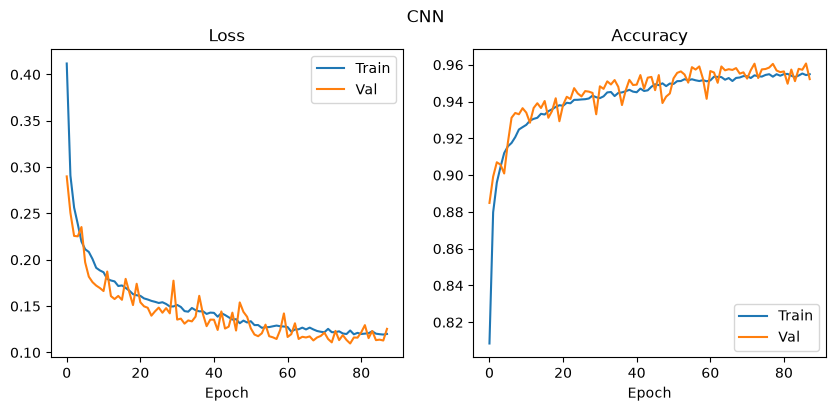

In [18]:
plot_learning_curves(
    train_loss_history_cnn,
    train_accuracy_history_cnn,
    val_loss_history_cnn,
    val_accuracy_history_cnn,
    title="CNN",
)

### b)

#### Використайте попередньо натреновану модель (наприклад, ResNet, EfficientNet, MobileNet або іншу pretrained CNN)

In [19]:
class PretrainedResNet(nn.Module):
    def __init__(self, out_features: int, img_size: int = 96):
        super().__init__()
        self.img_size = img_size
        self.register_buffer(
            "mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
        )
        self.register_buffer(
            "std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
        )   

        self.backbone = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        in_features = self.backbone.fc.in_features
        self.backbone.fc = nn.Linear(in_features, out_features)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = F.interpolate(
            x,
            size=(self.img_size, self.img_size),
            mode="bilinear",
            align_corners=False,
        )
        x = (x - self.mean) / self.std # type: ignore
        return self.backbone(x)

#### Замініть вихідний класифікатор відповідно до кількості класів вашого датасету та проведіть донавчання моделі

In [20]:
model_resnet = PretrainedResNet(out_features=len(img_labels), img_size=96).to(device)

num_params = sum(p.numel() for p in model_resnet.parameters() if p.requires_grad)
print("Trainable params:", num_params)
print()

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_resnet.parameters(), lr=1e-4, weight_decay=1e-3)

patience = 10
n_epochs = 100
best_model_path_resnet = "best_model_resnet.pth"
batch_size = 256

(
    train_loss_history_resnet,
    train_accuracy_history_resnet,
    val_loss_history_resnet,
    val_accuracy_history_resnet,
) = train_and_eval(
    model_resnet,
    criterion,
    optimizer,
    patience,
    n_epochs,
    best_model_path_resnet,
    len(train_dataset),
    len(val_dataset),
    train_loader_cnn,
    val_loader_cnn,
    device,
)

Trainable params: 11177538

[01] train_loss=0.1103 | train_accuracy=0.9563 | val_loss=0.0661 | val_accuracy=0.9755
Saved best model
[02] train_loss=0.0289 | train_accuracy=0.9892 | val_loss=0.0672 | val_accuracy=0.9765
[03] train_loss=0.0172 | train_accuracy=0.9937 | val_loss=0.0756 | val_accuracy=0.9769
[04] train_loss=0.0162 | train_accuracy=0.9941 | val_loss=0.1229 | val_accuracy=0.9701
[05] train_loss=0.0168 | train_accuracy=0.9937 | val_loss=0.0649 | val_accuracy=0.9786
Saved best model
[06] train_loss=0.0129 | train_accuracy=0.9951 | val_loss=0.0746 | val_accuracy=0.9761
[07] train_loss=0.0146 | train_accuracy=0.9946 | val_loss=0.1237 | val_accuracy=0.9661
[08] train_loss=0.0130 | train_accuracy=0.9953 | val_loss=0.0592 | val_accuracy=0.9792
Saved best model
[09] train_loss=0.0124 | train_accuracy=0.9955 | val_loss=0.0684 | val_accuracy=0.9787
[10] train_loss=0.0131 | train_accuracy=0.9954 | val_loss=0.0641 | val_accuracy=0.9787
[11] train_loss=0.0119 | train_accuracy=0.9957 | va

## Порівняйте CNN, навчену з нуля, та pretrained модель:  якість класифікації;  процес і швидкість збіжності;  learning curves;  вплив обсягу тренувальних даних

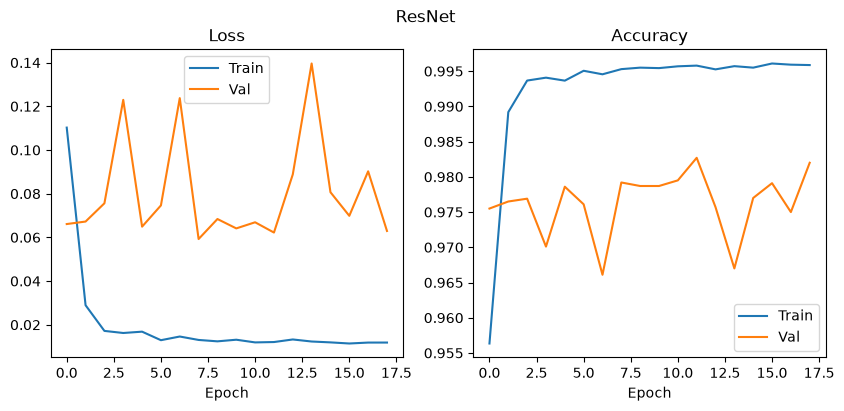

In [21]:
plot_learning_curves(
    train_loss_history_resnet,
    train_accuracy_history_resnet,
    val_loss_history_resnet,
    val_accuracy_history_resnet,
    title="ResNet",
)

In [22]:
test_cache_path = datapath / "../test_cache_path.pt"
if test_cache_path.exists():
    x_all, y_all = torch.load(test_cache_path, weights_only=True)
    test_tensor_dataset = TensorDataset(x_all.to(device), y_all.to(device))
else:
    test_tensor_dataset = preload_to_device(test_dataset, device)
    torch.save(test_tensor_dataset.tensors, test_cache_path)

test_loader_cnn = DataLoader(test_tensor_dataset, batch_size=512, shuffle=False)


def predict_classes(model: nn.Module, loader: DataLoader) -> tuple[np.ndarray, np.ndarray]:
    model.eval()
    preds, targets_all = [], []
    with torch.no_grad():
        for x, y in loader:
            out = model(x)
            preds.append(out.argmax(dim=1).cpu().numpy())
            targets_all.append(y.cpu().numpy())
    return np.concatenate(targets_all), np.concatenate(preds)


model_cnn.load_state_dict(torch.load(best_model_path_cnn, weights_only=True))
y_true_img, y_pred_cnn = predict_classes(model_cnn, test_loader_cnn)

model_resnet.load_state_dict(torch.load(best_model_path_resnet, weights_only=True))
_, y_pred_resnet = predict_classes(model_resnet, test_loader_cnn)

cnn_score = accuracy_score(y_true_img, y_pred_cnn)
print(f"CNN Test accuracy: {cnn_score:.4f}")
print(classification_report(y_true_img, y_pred_cnn, target_names=img_labels_str))

resnet_score = accuracy_score(y_true_img, y_pred_resnet)
print(f"ResNet18 Test accuracy: {resnet_score:.4f}")
print(classification_report(y_true_img, y_pred_resnet, target_names=img_labels_str))

CNN Test accuracy: 0.9587
              precision    recall  f1-score   support

        FAKE       0.96      0.96      0.96     10000
        REAL       0.96      0.96      0.96     10000

    accuracy                           0.96     20000
   macro avg       0.96      0.96      0.96     20000
weighted avg       0.96      0.96      0.96     20000

ResNet18 Test accuracy: 0.9808
              precision    recall  f1-score   support

        FAKE       0.98      0.98      0.98     10000
        REAL       0.98      0.98      0.98     10000

    accuracy                           0.98     20000
   macro avg       0.98      0.98      0.98     20000
weighted avg       0.98      0.98      0.98     20000



In [23]:
small_generator = torch.Generator().manual_seed(random_state)
small_train_dataset, _ = random_split(train_dataset, [0.1, 0.9], generator=small_generator)
small_train_loader = DataLoader(small_train_dataset, batch_size=batch_size, shuffle=True)

In [24]:
patience = 10
n_epochs = 100
batch_size = 256

in_features = sample_img.shape[0]
out_features = len(img_labels)
small_model_cnn = CNN(in_features, out_features).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(small_model_cnn.parameters(), lr=1e-3, weight_decay=1e-3)

best_model_path_small_cnn = "small_best_model_cnn.pth"
(
    small_train_loss_history_cnn,
    small_train_accuracy_history_cnn,
    small_val_loss_history_cnn,
    small_val_accuracy_history_cnn,
) = train_and_eval(
    small_model_cnn,
    criterion,
    optimizer,
    patience,
    n_epochs,
    best_model_path_small_cnn,
    len(small_train_dataset),
    len(val_dataset),
    small_train_loader,
    val_loader_cnn,
    device,
)

small_model_resnet = PretrainedResNet(out_features=len(img_labels), img_size=96).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(small_model_resnet.parameters(), lr=1e-4, weight_decay=1e-3)

best_model_path_small_resnet = "small_best_model_resnet.pth"
(
    small_train_loss_history_resnet,
    small_train_accuracy_history_resnet,
    small_val_loss_history_resnet,
    small_val_accuracy_history_resnet,
) = train_and_eval(
    small_model_resnet,
    criterion,
    optimizer,
    patience,
    n_epochs,
    best_model_path_small_resnet,
    len(small_train_dataset),
    len(val_dataset),
    small_train_loader,
    val_loader_cnn,
    device,
)

[01] train_loss=0.6052 | train_accuracy=0.6684 | val_loss=0.5171 | val_accuracy=0.7375
Saved best model
[02] train_loss=0.4812 | train_accuracy=0.7633 | val_loss=0.4639 | val_accuracy=0.7757
Saved best model
[03] train_loss=0.4446 | train_accuracy=0.7863 | val_loss=0.4218 | val_accuracy=0.8051
Saved best model
[04] train_loss=0.4049 | train_accuracy=0.8139 | val_loss=0.3883 | val_accuracy=0.8275
Saved best model
[05] train_loss=0.3778 | train_accuracy=0.8352 | val_loss=0.4384 | val_accuracy=0.7870
[06] train_loss=0.3637 | train_accuracy=0.8418 | val_loss=0.3434 | val_accuracy=0.8567
Saved best model
[07] train_loss=0.3451 | train_accuracy=0.8530 | val_loss=0.3708 | val_accuracy=0.8448
[08] train_loss=0.3334 | train_accuracy=0.8631 | val_loss=0.3523 | val_accuracy=0.8563
[09] train_loss=0.3440 | train_accuracy=0.8537 | val_loss=0.3618 | val_accuracy=0.8312
[10] train_loss=0.3309 | train_accuracy=0.8639 | val_loss=0.3488 | val_accuracy=0.8433
[11] train_loss=0.3115 | train_accuracy=0.870

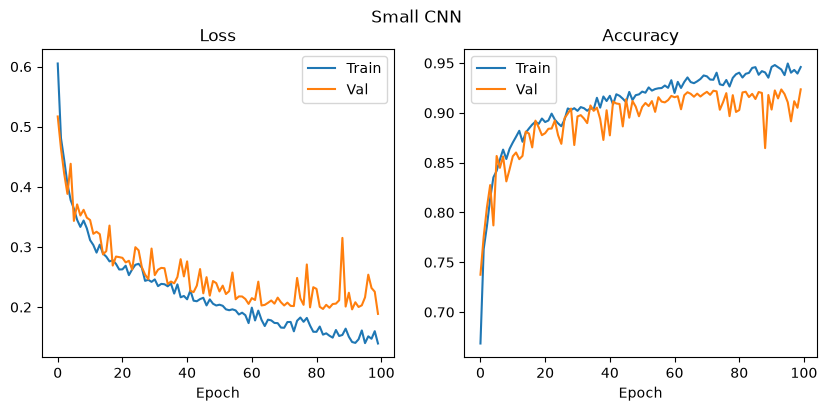

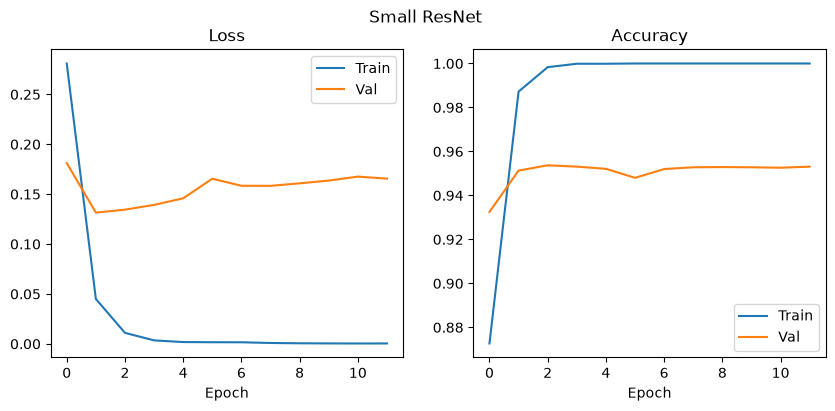

In [25]:
plot_learning_curves(
    small_train_loss_history_cnn,
    small_train_accuracy_history_cnn,
    small_val_loss_history_cnn,
    small_val_accuracy_history_cnn,
    title="Small CNN",
)
plot_learning_curves(
    small_train_loss_history_resnet,
    small_train_accuracy_history_resnet,
    small_val_loss_history_resnet,
    small_val_accuracy_history_resnet,
    title="Small ResNet",
)

In [26]:
small_model_cnn.load_state_dict(torch.load(best_model_path_small_cnn, weights_only=True))
y_true_img, small_y_pred_cnn = predict_classes(small_model_cnn, test_loader_cnn)

small_model_resnet.load_state_dict(torch.load(best_model_path_small_resnet, weights_only=True))
_, small_y_pred_resnet = predict_classes(small_model_resnet, test_loader_cnn)

small_cnn_score = accuracy_score(y_true_img, small_y_pred_cnn)
print(f"Small CNN Test accuracy: {small_cnn_score:.4f}")
print(classification_report(y_true_img, small_y_pred_cnn, target_names=img_labels_str))

small_resnet_score = accuracy_score(y_true_img, small_y_pred_resnet)
print(f"Small ResNet18 Test accuracy: {small_resnet_score:.4f}")
print(classification_report(y_true_img, small_y_pred_resnet, target_names=img_labels_str))

Small CNN Test accuracy: 0.9217
              precision    recall  f1-score   support

        FAKE       0.93      0.91      0.92     10000
        REAL       0.91      0.93      0.92     10000

    accuracy                           0.92     20000
   macro avg       0.92      0.92      0.92     20000
weighted avg       0.92      0.92      0.92     20000

Small ResNet18 Test accuracy: 0.9505
              precision    recall  f1-score   support

        FAKE       0.96      0.94      0.95     10000
        REAL       0.94      0.96      0.95     10000

    accuracy                           0.95     20000
   macro avg       0.95      0.95      0.95     20000
weighted avg       0.95      0.95      0.95     20000



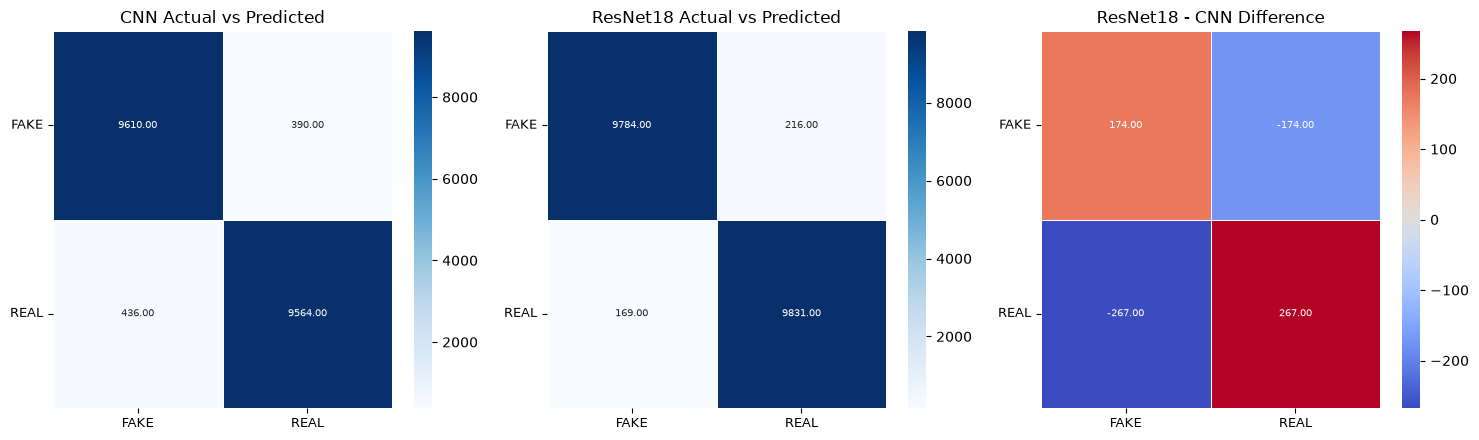

In [27]:
cm_cnn = confusion_matrix(y_true_img, y_pred_cnn)
cm_resnet = confusion_matrix(y_true_img, y_pred_resnet)

cnn_model_result = ModelResult(
    name="CNN",
    confusion_matrix=cm_cnn,
    accuracy_score=float(cnn_score),
)
resnet_model_result = ModelResult(
    name="ResNet18",
    confusion_matrix=cm_resnet,
    accuracy_score=float(resnet_score),
)
diff_img_result = resnet_model_result - cnn_model_result
max_diff = float(np.abs(diff_img_result.confusion_matrix).max())

fig, (ax1, ax2, ax3) = plt.subplots(ncols=3, figsize=(15, 4.5))

plot_heatmap(
    dataframe=cm_cnn,
    xticklabels=img_labels_str,
    yticklabels=img_labels_str,
    cmap="Blues",
    title_name="CNN Actual vs Predicted",
    ax=ax1,
    rotation=0
)
plot_heatmap(
    dataframe=cm_resnet,
    xticklabels=img_labels_str,
    yticklabels=img_labels_str,
    cmap="Blues",
    title_name="ResNet18 Actual vs Predicted",
    ax=ax2,
    rotation=0
)
plot_heatmap(
    dataframe=diff_img_result.confusion_matrix,
    xticklabels=img_labels_str,
    yticklabels=img_labels_str,
    cmap="coolwarm",
    vmin=-max_diff,
    vmax=max_diff,
    title_name="ResNet18 - CNN Difference",
    ax=ax3,
    rotation=0
)

plt.tight_layout()
plt.show()

**Якість класифікації.** Попередньо навчена модель забезпечує вищу точність та кращий баланс між влучністю й повнотою на тестовій вибірці при 0.9808 проти 0.9587 та макро-F1 0.98 проти 0.96. Згорткова мережа з випадковою ініціалізацією ваг змушена виділяти базові візуальні примітиви самостійно, через що, імовірно, частіше помиляється на складних прикладах. Попередньо навчена архітектура вже має сформовані фільтри для виявлення контурів, текстур і просторових структур, тому, імовірно, краще розпізнає дрібні спотворення та специфічні ознаки класів.

**Процес і швидкість збіжності.** Навчання з нуля потребує значно більше епох, 88 проти 18, оскільки, імовірно, нижні згорткові шари довго налаштовують базові детектори ознак, і лише після цього класифікатор починає будувати розділяючу межу. Попередньо навчена модель стартує з уже впорядкованого простору ознак, тому функція втрат стрімко знижується вже протягом перших кількох епох, при val accuracy = 0.9755 уже на першій, а донавчання всіх шарів із малим кроком `lr = 1e-4` лише підлаштовує вже наявні фільтри під задачу.

**Криві навчання.** CNN з нуля збігається повільно: loss плавно спадає протягом приблизно 88 епох, train і validation loss близькі, 0.120 і 0.126 на останній епосі, перенавчання немає, а валідаційна крива помітно коливається. ResNet18 досягає високої якості вже на першій епосі, найкращий val loss = 0.0592 має на епосі 8 при val accuracy = 0.9792, після чого val loss коливається в межах 0.059-0.14 без стійкого покращення, тоді як train loss значно нижчий за валідаційний, тобто модель швидко переходить у режим перенавчання, яке стримує рання зупинка.

**Вплив обсягу тренувальних даних.** При зменшенні вибірки до 10%, тобто до 9 000 зображень, точність CNN падає з 0.9587 до 0.9217, а ResNet18 -- з 0.9808 до 0.9505. Попередньо навчена модель на 9 000 зображень майже досягає результату CNN з нуля на 90 000, 0.9505 проти 0.9587. Водночас на малій вибірці ResNet18 схильний до перенавчання: train accuracy дорівнює 1.0, а val loss зростає з 0.1315 на епосі 2 до 0.17 і вище, тож перевага pretrained-моделі зберігається, але не усуває потреби в ранній зупинці. Мала CNN пройшла всі 100 епох без ранньої зупинки, тому її результат може бути дещо занижений.

## Зробіть висновки

Перенесення навчання в ResNet18 дає вищу точність, а саме 0.9808 проти 0.9587, і значно швидшу збіжність, 18 епох проти 88, порівняно з простою CNN з нуля, а на 10% даних перевага зберігається, 0.9505 проти 0.9217, хоча pretrained-модель на малій вибірці теж перенавчається. Проста CNN, натомість, не перенавчається на повних даних і має набагато менше параметрів, 150 тис. проти 11 млн, тому залишається прийнятним варіантом, якщо важливі розмір моделі та вартість обчислень.

# 3. Нейронні мережі для класифікації текстів
1. Використайте той самий текстовий датасет, з яким ви працювали в лабораторній роботі №2.
1. Проведіть необхідну передобробку текстових даних: токенізацію, побудову словника, перетворення токенів в індекси та приведення послідовностей до однакової довжини (padding/truncation).
1. Вирішіть задачу класифікації двома способами.
1. 
    1. а)
        1. Побудуйте модель з Embedding layer, ініціалізованим випадковими вагами.
        1. Використайте RNN / LSTM / GRU для класифікації та навчіть модель на своєму датасеті.
    1. б)
        1. Завантажте готові pretrained embeddings (наприклад, GloVe) та ініціалізуйте ними Embedding layer.
        1. Проведіть навчання моделі.
1. Для обох моделей побудуйте learning curves (train/validation loss).
1. Порівняйте результати двох підходів:  якість класифікації;  швидкість і стабільність навчання;  вплив pretrained embeddings на отриманий результат.
1. Зробіть висновки.

## Використайте той самий текстовий датасет, з яким ви працювали в лабораторній роботі №2

In [28]:
datapath_lab_2 = Path("../lab2/data/train.csv")
raw_data_lab_2 = pd.read_csv(datapath_lab_2)

raw_texts = raw_data_lab_2["text"]
targets = raw_data_lab_2["model"]

label_encoder = LabelEncoder()
encoded_targets = label_encoder.fit_transform(targets)
text_labels = label_encoder.classes_
num_classes = len(text_labels)

raw_train_full, raw_test, y_train_full, y_test = train_test_split(
    raw_texts,
    encoded_targets,
    random_state=random_state,
    test_size=0.15,
    stratify=encoded_targets,
)

raw_train, raw_val, y_train, y_val = train_test_split(
    raw_train_full,
    y_train_full,
    random_state=random_state,
    test_size=0.15,
    stratify=y_train_full,
)

## Проведіть необхідну передобробку текстових даних: токенізацію, побудову словника, перетворення токенів в індекси та приведення послідовностей до однакової довжини (padding/truncation)

In [29]:
pad_token = "<pad>"
unk_token = "<unk>"
pad_idx = 0
unk_idx = 1
max_len = 256


def tokenize(text: str) -> list[str]:
    return re.findall(r"\w+|[^\w\s]", str(text).lower())


def build_vocab(
    texts: pd.Series, min_freq: int = 2, max_size: int = 25000
) -> dict[str, int]:
    counter: Counter[str] = Counter()
    for text in texts:
        counter.update(tokenize(text))

    vocab = {pad_token: pad_idx, unk_token: unk_idx}
    for token, freq in counter.most_common(max_size - 2):
        if freq < min_freq:
            break
        vocab[token] = len(vocab)
    return vocab


def encode_and_pad(
    texts: pd.Series, vocab: dict[str, int], max_len: int = max_len
) -> torch.Tensor:
    encoded = np.full((len(texts), max_len), pad_idx, dtype=np.int64)
    for idx, text in enumerate(texts):
        tokens = tokenize(text)[:max_len]
        token_ids = [vocab.get(token, unk_idx) for token in tokens]
        encoded[idx, : len(token_ids)] = token_ids
    return torch.tensor(encoded, dtype=torch.long)


vocab = build_vocab(raw_train, min_freq=2, max_size=25000)

X_train_seq = encode_and_pad(raw_train, vocab, max_len)
X_val_seq = encode_and_pad(raw_val, vocab, max_len)
X_test_seq = encode_and_pad(raw_test, vocab, max_len)

train_loader_txt = DataLoader(
    TensorDataset(X_train_seq.to(device), torch.tensor(y_train, dtype=torch.long, device=device)),
    batch_size=64,
    shuffle=True,
)
val_loader_txt = DataLoader(
    TensorDataset(X_val_seq.to(device), torch.tensor(y_val, dtype=torch.long, device=device)),
    batch_size=128,
    shuffle=False,
)
test_loader_txt = DataLoader(
    TensorDataset(X_test_seq.to(device), torch.tensor(y_test, dtype=torch.long, device=device)),
    batch_size=128,
    shuffle=False,
)

## Вирішіть задачу класифікації двома способами

### a)

#### Побудуйте модель з Embedding layer, ініціалізованим випадковими вагами

In [30]:
class TextGRUClassifier(nn.Module):
    def __init__(
        self,
        vocab_size: int,
        embed_dim: int,
        hidden_dim: int,
        num_classes: int,
        pretrained_embeddings: torch.Tensor | None = None,
        freeze_embeddings: bool = False,
        dropout: float = 0.3,
    ):
        super().__init__()
        if pretrained_embeddings is not None:
            self.embedding = nn.Embedding.from_pretrained(
                pretrained_embeddings,
                freeze=freeze_embeddings,
                padding_idx=pad_idx,
            )
        else:
            self.embedding = nn.Embedding(
                vocab_size, embed_dim, padding_idx=pad_idx
            )

        self.gru = nn.GRU(
            embed_dim,
            hidden_dim,
            batch_first=True,
            bidirectional=True,
        )
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim * 2, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        mask = (x != pad_idx).unsqueeze(-1).float()
        embedded = self.dropout(self.embedding(x))
        outputs, _ = self.gru(embedded)
        pooled = (outputs * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1.0)
        return self.classifier(self.dropout(pooled))


embed_dim = 100
hidden_dim = 128

model_gru_rnd = TextGRUClassifier(
    vocab_size=len(vocab),
    embed_dim=embed_dim,
    hidden_dim=hidden_dim,
    num_classes=num_classes,
).to(device)
print(model_gru_rnd)

TextGRUClassifier(
  (embedding): Embedding(10781, 100, padding_idx=0)
  (gru): GRU(100, 128, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Linear(in_features=256, out_features=18, bias=True)
)


#### Використайте RNN / LSTM / GRU для класифікації та навчіть модель на своєму датасеті

In [31]:
num_params = sum(p.numel() for p in model_gru_rnd.parameters() if p.requires_grad)
print("Trainable params:", num_params)
print()

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_gru_rnd.parameters(), lr=1e-3, weight_decay=1e-4)

patience = 5
n_epochs = 30
best_model_path_gru_rnd = "best_model_gru_rnd.pth"

(
    train_loss_history_gru_rnd,
    train_accuracy_history_gru_rnd,
    val_loss_history_gru_rnd,
    val_accuracy_history_gru_rnd,
) = train_and_eval(
    model_gru_rnd,
    criterion,
    optimizer,
    patience,
    n_epochs,
    best_model_path_gru_rnd,
    len(X_train_seq),
    len(X_val_seq),
    train_loader_txt,
    val_loader_txt,
    device,
)

Trainable params: 1259366

[01] train_loss=2.8815 | train_accuracy=0.0739 | val_loss=2.8522 | val_accuracy=0.1188
Saved best model
[02] train_loss=2.8008 | train_accuracy=0.1313 | val_loss=2.6848 | val_accuracy=0.0986
Saved best model
[03] train_loss=2.5915 | train_accuracy=0.1611 | val_loss=2.4805 | val_accuracy=0.1652
Saved best model
[04] train_loss=2.3803 | train_accuracy=0.2104 | val_loss=2.3372 | val_accuracy=0.1855
Saved best model
[05] train_loss=2.2413 | train_accuracy=0.2273 | val_loss=2.2179 | val_accuracy=0.1768
Saved best model
[06] train_loss=2.1116 | train_accuracy=0.2401 | val_loss=2.2086 | val_accuracy=0.1971
Saved best model
[07] train_loss=2.0566 | train_accuracy=0.2499 | val_loss=2.1767 | val_accuracy=0.2116
Saved best model
[08] train_loss=1.9850 | train_accuracy=0.2699 | val_loss=2.1798 | val_accuracy=0.2116
[09] train_loss=1.9375 | train_accuracy=0.2889 | val_loss=2.1866 | val_accuracy=0.2116
[10] train_loss=1.8869 | train_accuracy=0.2960 | val_loss=2.1572 | val_

### b)

#### Завантажте готові pretrained embeddings (наприклад, GloVe) та ініціалізуйте ними Embedding layer

In [32]:
import urllib.request
import zipfile


def load_glove_matrix(
    vocab: dict[str, int],
    embed_dim: int = 100,
    cache_dir: str = "../lab3/glove",
) -> torch.Tensor:
    cache_path = Path(cache_dir)
    cache_path.mkdir(parents=True, exist_ok=True)
    glove_txt = cache_path / f"glove.6B.{embed_dim}d.txt"
    glove_zip = cache_path / "glove.6B.zip"

    if not glove_txt.exists():
        if not glove_zip.exists():
            url = "https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.zip"
            urllib.request.urlretrieve(url, glove_zip)
        with zipfile.ZipFile(glove_zip, "r") as zf:
            zf.extract(f"glove.6B.{embed_dim}d.txt", path=cache_path)

    rng = np.random.default_rng(random_state)
    matrix = rng.normal(scale=0.1, size=(len(vocab), embed_dim)).astype(np.float32)
    matrix[pad_idx] = np.zeros(embed_dim, dtype=np.float32)

    matched = 0
    with open(glove_txt, encoding="utf-8") as f:
        for line in f:
            parts = line.rstrip().split(" ")
            token = parts[0]
            if token in vocab:
                matrix[vocab[token]] = np.asarray(parts[1:], dtype=np.float32)
                matched += 1

    print(f"Loaded GloVe vectors for {matched}/{len(vocab)} vocabulary tokens")
    return torch.tensor(matrix)


glove_matrix = load_glove_matrix(vocab, embed_dim=embed_dim)

model_gru_glv = TextGRUClassifier(
    vocab_size=len(vocab),
    embed_dim=embed_dim,
    hidden_dim=hidden_dim,
    num_classes=num_classes,
    pretrained_embeddings=glove_matrix,
    freeze_embeddings=False,
).to(device)

Loaded GloVe vectors for 10708/10781 vocabulary tokens


#### Проведіть навчання моделі

In [33]:
model_gru_glv = TextGRUClassifier(
    vocab_size=len(vocab),
    embed_dim=embed_dim,
    hidden_dim=hidden_dim,
    num_classes=num_classes,
    pretrained_embeddings=glove_matrix,
    freeze_embeddings=False,
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_gru_glv.parameters(), lr=1e-3, weight_decay=1e-4)

best_model_path_gru_glv = "best_model_gru_glv.pth"

(
    train_loss_history_gru_glv,
    train_accuracy_history_gru_glv,
    val_loss_history_gru_glv,
    val_accuracy_history_gru_glv,
) = train_and_eval(
    model_gru_glv,
    criterion,
    optimizer,
    patience,
    n_epochs,
    best_model_path_gru_glv,
    len(X_train_seq),
    len(X_val_seq),
    train_loader_txt,
    val_loader_txt,
    device,
)

[01] train_loss=2.8933 | train_accuracy=0.0580 | val_loss=2.8658 | val_accuracy=0.0986
Saved best model
[02] train_loss=2.8139 | train_accuracy=0.0970 | val_loss=2.6329 | val_accuracy=0.1014
Saved best model
[03] train_loss=2.6117 | train_accuracy=0.1190 | val_loss=2.4717 | val_accuracy=0.1478
Saved best model
[04] train_loss=2.4852 | train_accuracy=0.1283 | val_loss=2.4652 | val_accuracy=0.1333
Saved best model
[05] train_loss=2.4072 | train_accuracy=0.1442 | val_loss=2.3292 | val_accuracy=0.1768
Saved best model
[06] train_loss=2.3399 | train_accuracy=0.1606 | val_loss=2.3169 | val_accuracy=0.1652
Saved best model
[07] train_loss=2.2390 | train_accuracy=0.1852 | val_loss=2.2607 | val_accuracy=0.1565
Saved best model
[08] train_loss=2.1344 | train_accuracy=0.2129 | val_loss=2.1831 | val_accuracy=0.1913
Saved best model
[09] train_loss=2.0066 | train_accuracy=0.2468 | val_loss=2.0819 | val_accuracy=0.2232
Saved best model
[10] train_loss=1.8991 | train_accuracy=0.2576 | val_loss=2.0409

## Для обох моделей побудуйте learning curves (train/validation loss)

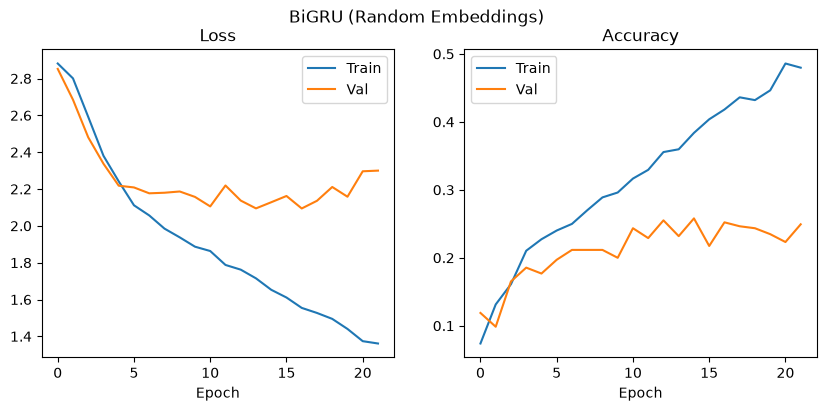

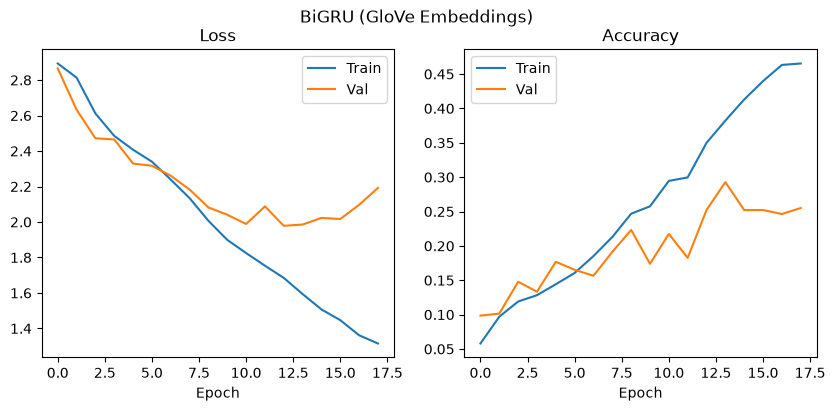

In [34]:
plot_learning_curves(
    train_loss_history_gru_rnd,
    train_accuracy_history_gru_rnd,
    val_loss_history_gru_rnd,
    val_accuracy_history_gru_rnd,
    title="BiGRU (Random Embeddings)",
)
plot_learning_curves(
    train_loss_history_gru_glv,
    train_accuracy_history_gru_glv,
    val_loss_history_gru_glv,
    val_accuracy_history_gru_glv,
    title="BiGRU (GloVe Embeddings)",
)

## Порівняйте результати двох підходів:  якість класифікації;  швидкість і стабільність навчання;  вплив pretrained embeddings на отриманий результат

BiGRU Random Test accuracy: 0.2370
                        precision    recall  f1-score   support

        claude-fable-5       0.25      0.27      0.26        22
       claude-opus-4-6       0.22      0.36      0.28        22
       claude-opus-4-8       0.33      0.14      0.19        22
         claude-opus-5       0.30      0.43      0.36        23
       claude-sonnet-5       0.22      0.17      0.20        23
gemini-3.1-pro-preview       0.64      0.61      0.62        23
      gemini-3.6-flash       0.41      0.32      0.36        22
      gemini-3.7-flash       0.33      0.17      0.23        23
      gemini-3.8-flash       0.33      0.57      0.41        23
               glm-5.3       0.13      0.18      0.15        22
         glm-5.3-flash       0.20      0.04      0.07        23
               gpt-5.5       0.13      0.26      0.17        23
          gpt-5.6-luna       0.10      0.05      0.06        22
           gpt-5.6-sol       0.03      0.04      0.04        23
    

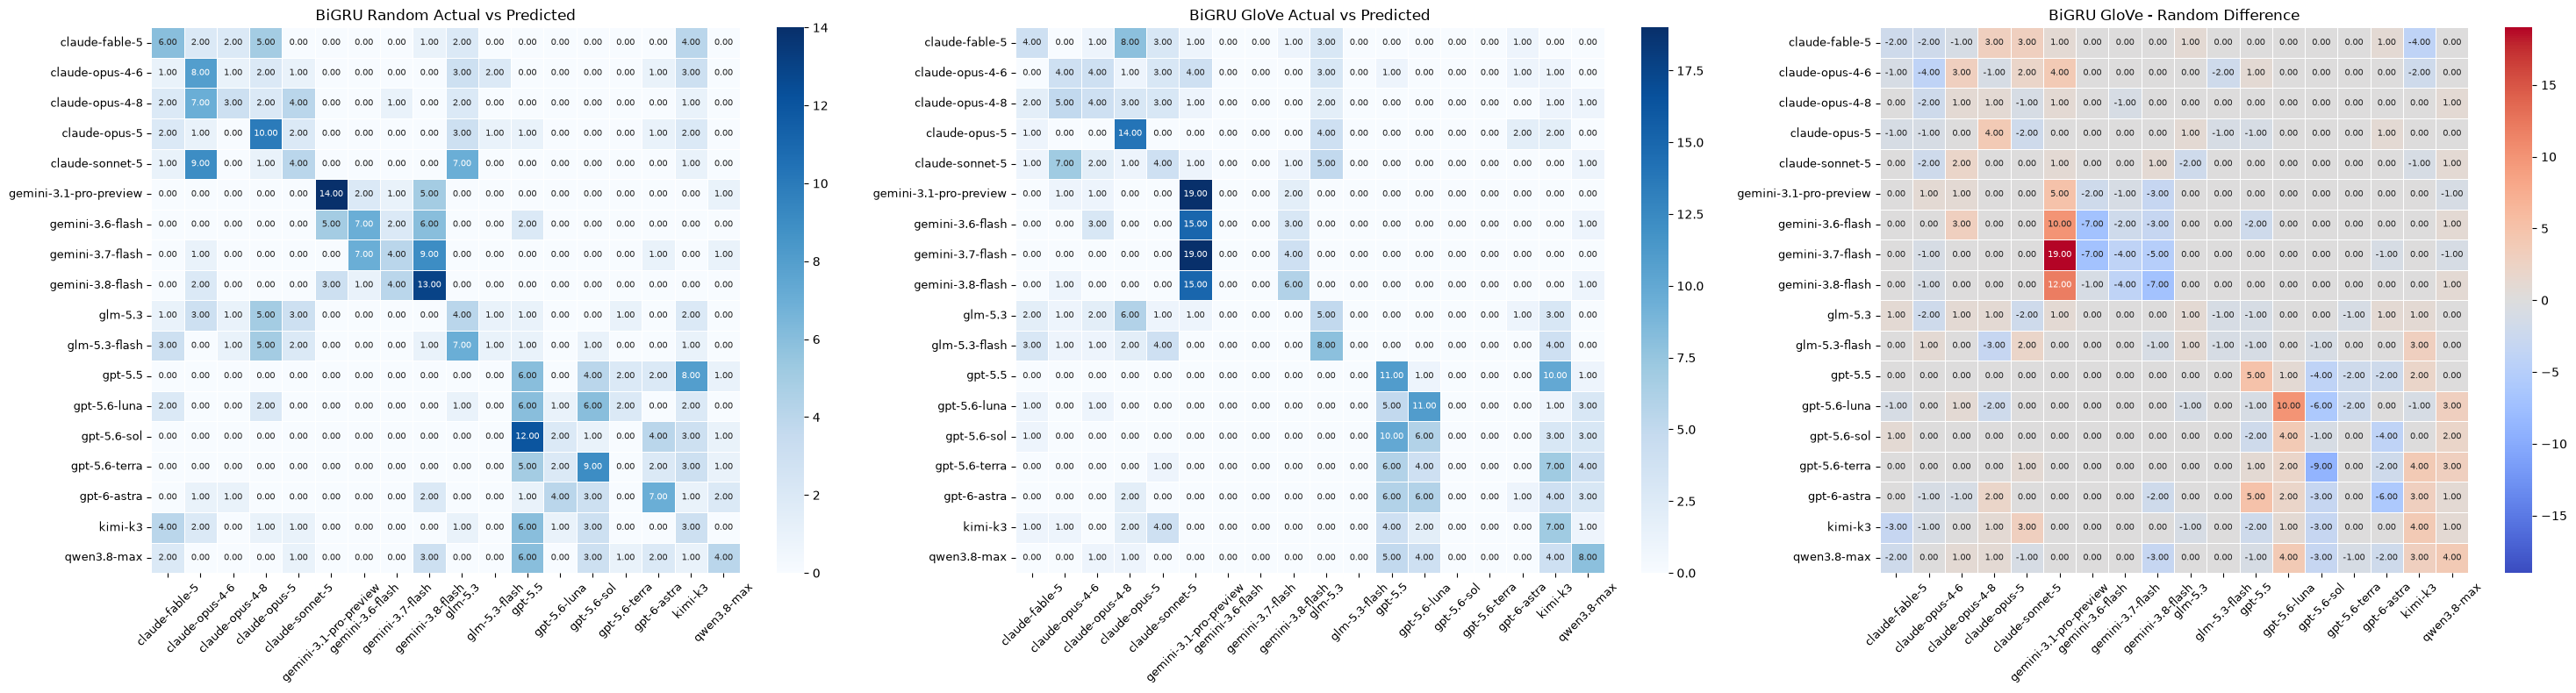

In [35]:
model_gru_rnd.load_state_dict(torch.load(best_model_path_gru_rnd, weights_only=True))
y_true_txt, y_pred_gru_rnd = predict_classes(model_gru_rnd, test_loader_txt)

model_gru_glv.load_state_dict(torch.load(best_model_path_gru_glv, weights_only=True))
_, y_pred_gru_glv = predict_classes(model_gru_glv, test_loader_txt)

gru_rnd_score = accuracy_score(y_true_txt, y_pred_gru_rnd)
print(f"BiGRU Random Test accuracy: {gru_rnd_score:.4f}")
print(classification_report(y_true_txt, y_pred_gru_rnd, target_names=text_labels, zero_division=0))

gru_glv_score = accuracy_score(y_true_txt, y_pred_gru_glv)
print(f"BiGRU GloVe Test accuracy: {gru_glv_score:.4f}")
print(classification_report(y_true_txt, y_pred_gru_glv, target_names=text_labels, zero_division=0))

cm_gru_rnd = confusion_matrix(y_true_txt, y_pred_gru_rnd)
cm_gru_glv = confusion_matrix(y_true_txt, y_pred_gru_glv)

gru_rnd_result = ModelResult(
    name="BiGRU Random",
    confusion_matrix=cm_gru_rnd,
    accuracy_score=float(gru_rnd_score),
)
gru_glv_result = ModelResult(
    name="BiGRU GloVe",
    confusion_matrix=cm_gru_glv,
    accuracy_score=float(gru_glv_score),
)
diff_txt_result = gru_glv_result - gru_rnd_result
max_diff_txt = float(np.abs(diff_txt_result.confusion_matrix).max())

fig, (ax1, ax2, ax3) = plt.subplots(ncols=3, figsize=(30, 8))

plot_heatmap(
    dataframe=cm_gru_rnd,
    xticklabels=text_labels,
    yticklabels=text_labels,
    cmap="Blues",
    title_name="BiGRU Random Actual vs Predicted",
    ax=ax1,
    rotation=45,
)
plot_heatmap(
    dataframe=cm_gru_glv,
    xticklabels=text_labels,
    yticklabels=text_labels,
    cmap="Blues",
    title_name="BiGRU GloVe Actual vs Predicted",
    ax=ax2,
    rotation=45,
)
plot_heatmap(
    dataframe=diff_txt_result.confusion_matrix,
    xticklabels=text_labels,
    yticklabels=text_labels,
    cmap="coolwarm",
    vmin=-max_diff_txt,
    vmax=max_diff_txt,
    title_name="BiGRU GloVe - Random Difference",
    ax=ax3,
    rotation=45,
)

plt.tight_layout()
plt.show()

BiGRU Random Family accuracy: 0.6420
              precision    recall  f1-score   support

      claude       0.63      0.68      0.66       112
      gemini       0.91      0.91      0.91        91
         glm       0.37      0.29      0.33        45
         gpt       0.72      0.72      0.72       112
        kimi       0.09      0.14      0.11        22
        qwen       0.36      0.17      0.24        23

    accuracy                           0.64       405
   macro avg       0.51      0.49      0.49       405
weighted avg       0.64      0.64      0.64       405

BiGRU GloVe Family accuracy: 0.6247
              precision    recall  f1-score   support

      claude       0.62      0.67      0.65       112
      gemini       0.89      0.91      0.90        91
         glm       0.43      0.29      0.35        45
         gpt       0.76      0.60      0.67       112
        kimi       0.15      0.32      0.20        22
        qwen       0.30      0.35      0.32        23

    

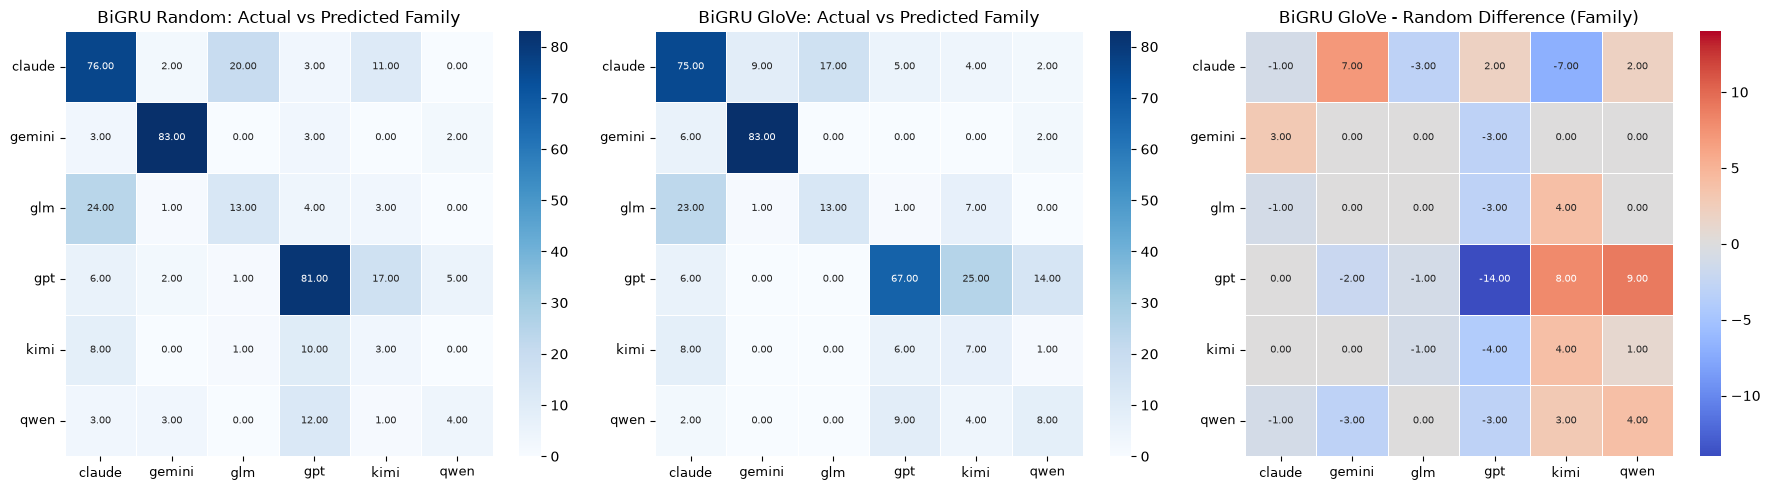

In [36]:
def get_family(name: str) -> str:
    return name.split("-")[0].replace("qwen3.8", "qwen")


fam_true = np.array([get_family(text_labels[i]) for i in y_true_txt])
fam_pred_gru_rnd = np.array([get_family(text_labels[i]) for i in y_pred_gru_rnd])
fam_pred_gru_glv = np.array([get_family(text_labels[i]) for i in y_pred_gru_glv])
family_labels = np.sort(np.unique(fam_true))

fam_rnd_score = accuracy_score(fam_true, fam_pred_gru_rnd)
print(f"BiGRU Random Family accuracy: {fam_rnd_score:.4f}")
print(classification_report(fam_true, fam_pred_gru_rnd, labels=family_labels, zero_division=0))

fam_glv_score = accuracy_score(fam_true, fam_pred_gru_glv)
print(f"BiGRU GloVe Family accuracy: {fam_glv_score:.4f}")
print(classification_report(fam_true, fam_pred_gru_glv, labels=family_labels, zero_division=0))

cm_fam_rnd = confusion_matrix(fam_true, fam_pred_gru_rnd, labels=family_labels)
cm_fam_glv = confusion_matrix(fam_true, fam_pred_gru_glv, labels=family_labels)

fam_rnd_result = ModelResult(
    name="BiGRU Random",
    confusion_matrix=cm_fam_rnd,
    accuracy_score=float(fam_rnd_score),
)
fam_glv_result = ModelResult(
    name="BiGRU GloVe",
    confusion_matrix=cm_fam_glv,
    accuracy_score=float(fam_glv_score),
)
diff_fam_result = fam_glv_result - fam_rnd_result
max_diff_fam = float(np.abs(diff_fam_result.confusion_matrix).max())

fig, (ax1, ax2, ax3) = plt.subplots(ncols=3, figsize=(18, 5))

plot_heatmap(
    dataframe=cm_fam_rnd,
    xticklabels=family_labels,
    yticklabels=family_labels,
    cmap="Blues",
    title_name="BiGRU Random: Actual vs Predicted Family",
    ax=ax1,
    rotation=0,
)
plot_heatmap(
    dataframe=cm_fam_glv,
    xticklabels=family_labels,
    yticklabels=family_labels,
    cmap="Blues",
    title_name="BiGRU GloVe: Actual vs Predicted Family",
    ax=ax2,
    rotation=0,
)
plot_heatmap(
    dataframe=diff_fam_result.confusion_matrix,
    xticklabels=family_labels,
    yticklabels=family_labels,
    cmap="coolwarm",
    vmin=-max_diff_fam,
    vmax=max_diff_fam,
    title_name="BiGRU GloVe - Random Difference (Family)",
    ax=ax3,
    rotation=0,
)

plt.tight_layout()
plt.show()

**Якість класифікації.** Моделі з випадковою ініціалізацією та з GloVe показали практично однакову тестову точність: 0.2370 і 0.2420, різниця становить 2 об'єкти з 405, а випадкове вгадування для 18 класів це приблизно 0.056. У попередньому запуску було 0.215 і 0.286, тож різниця між підходами лежить у межах розкиду від випадкової ініціалізації. TF-IDF із логістичною регресією з лабораторної роботи 2 дав 0.259, що трохи краще за обидві моделі.

**Швидкість і стабільність навчання.** Модель із GloVe досягає мінімуму validation loss раніше, 13 проти 17, і з трохи нижчим значенням, 1.98 проти 2.09, проте ця перевага не переходить у точність. До моменту зупинки розрив між train і validation accuracy в обох моделей великий, 0.48 проти 0.25 і 0.47 проти 0.26, тобто обидві перенавчаються, і рання зупинка потрібна для обох.

**Вплив pretrained embeddings.** У експерименті GloVe не дав помітного приросту якості і не усунув перенавчання. Імовірно, на невеликому корпусі з приблизно 2000 текстами і в задачі розпізнавання стилю, а не змісту, семантична інформація GloVe мало допомагає.

**Рівень родин.** Після агрегації передбачень до 6 родин accuracy становить 0.6420 для випадкових embeddings і 0.6247 для GloVe, що порівнянно з 0.657 у TF-IDF + LogReg з лабораторної роботи 2. Великі родини, як claude, gemini та gpt, розпізнаються добре, F1 = 0.65-0.91, а малі glm, kimi та qwen при 22-45 тестових прикладів залишаються слабкими, F1 = 0.11-0.35.

## Зробіть висновки

Ініціалізація embedding-шару GloVe не дала помітного покращення BiGRU порівняно з випадковою ініціалізацією: 0.242 проти 0.237 для 18 моделей і 0.625 проти 0.642 для 6 родин, причому різниця лежить у межах розкиду між запусками. Обидві моделі не усунули перенавчання на невеликому датасеті й трохи поступаються TF-IDF + LogReg з лабораторної роботи 2, де було 0.259 для 18 моделей і 0.657 для родин, тобто на приблизно 2000 текстів ані рекурентна мережа, ані pretrained embeddings не дали переваги над класичним підходом. Малі родини, як glm, kimi та qwen, розпізнаються слабко в усіх моделей. Вплив заморожування embedding-шару не досліджувався.